# WER Challenge

## Inhaltsverzeichnis

- [Vorwort](#vorwort)
- [Einleitung](#einleitung)
- [Definition der Fragestellung](#definition-der-fragestellung)
- [Hypothese](#hypothese)
- [Lösungsstrategie](#lösungsstrategie)
- [Einlesen von Dateien und kombinieren](#einlesen-von-dateien-und-kombinieren)
- [Systemdefinition](#systemdefinition)
- [Korrelations Plot](#korrelations-plot)
- [Analyse der Korrelationen](#analyse-der-korrelationen)
  - [Die Gesamtbewoelkung](#die-gesamtbewoelkung)
  - [Die Luftfeuchtigkeit](#die-luftfeuchtigkeit)
  - [Der Luftdruck](#der-luftdruck)
  - [Der Scope](#der-scope)
  - [Die Jahreszeiten - Faktor Zeit](#die-jahreszeiten---faktor-zeit)
- [Wahrscheinlichkeitsmodell](#wahrscheinlichkeitsmodell)
- [Abhängigkeiten und Unsicherheiten](#abhaengigkeiten-und-unsicherheiten)
- [Erweiterung durch neue Erkenntnisse](#erweiterung-durch-neue-erkenntnisse)

# Vorwort

Auf dieser Open Mini Challenge haben sich Michaela Brutenic, Roberto Fazekas und Emircan Bagcivan beteiligt.

# Einleitung
Die vorliegende Open Mini Challenge hat als Ziel die Entwicklung eines Wahrscheinlichkeitsmodells, das vorhersagt, ob es am nächsten Tag in Basel regnen wird. Grundlage für die Modellierung bilden regionale Wetterdaten aus den Jahren 2000 bis 2025, die eine Vielzahl meteorologischer Merkmale wie Temperatur, Luftfeuchtigkeit, Luftdruck, Windverhältnisse und Niederschlagsmengen enthalten.

Ziel ist es, auf Basis dieser Daten mithilfe klassischer Methoden der Wahrscheinlichkeitsrechnung – wie etwa bedingter Wahrscheinlichkeiten, Häufigkeitsverteilungen, Übergangswahrscheinlichkeiten oder auch einfacher stochastischer Modelle – ein mathematisches Modell zu konstruieren, dass die Regenwahrscheinlichkeit für den folge Tag beschreibt.

Die vollständige Datenlage erlaubt dabei eine fundierte Analyse, um die Abhängigkeiten zwischen Wettermerkmalen und Regenereignissen zu untersuchen. Das Modell soll dabei nicht nur eine Ja/Nein-Aussage treffen,  [sondern explizit die Wahrscheinlichkeit eines Regenereignisses angeben.]  Es bietet somit einen praktischen Anwendungsfall für stochastische Denkweisen im realweltlichen Kontext der Wettervorhersage.

Die Daten liegen in strukturierter Form vor und ermöglichen sowohl eine fundierte explorative Analyse als auch die Anwendung klassischer Verfahren der Wahrscheinlichkeitsrechnung. Ziel ist es, ein robustes, nachvollziehbares Modell zu entwickeln, das verlässliche Aussagen zur Regenwahrscheinlichkeit liefert 

# Definition der Fragestellung
Im Zentrum dieser Arbeit steht die folgende Fragestellung:

Wie lässt sich auf Grundlage historischer Wetterdaten die Wahrscheinlichkeit eines Regenereignisses für den folgenden Tag in Basel mathematisch modellieren?

Dabei sollen insbesondere stochastische Zusammenhänge zwischen verschiedenen meteorologischen Einflussgrößen und dem Auftreten von Regenereignissen identifiziert und in ein Wahrscheinlichkeitsmodell überführt werden. Das Ziel besteht darin, ein Modell zu entwickeln, das auf klar definierten, datenbasierten Regeln beruht und eine quantifizierte Vorhersage zur Regenwahrscheinlichkeit erlaubt – anstelle einer binären Entscheidung. Was unsere Fragestellung klar zu einer probabilistischen Fragestellung macht. Wir interessieren uns nicht für eine klare Ja / Nein Aussage, sondern für die Wahrscheinlichkeit - zu wie viel
Prozent es regnet.

# Hypothese
Es besteht ein signifikanter Zusammenhang zwischen bestimmten meteorologischen Variablen (z.B. Luftfeuchtigkeit, Bewölkung) und der Wahrscheinlichkeit des
Auftretens von Niederschlag. Ein geeignetes Wahrscheinlichkeitsmodell kann verwendet werden, um diesen Zusammenhang zu quantifizieren und zu prognostizieren.


# Lösungsstrategie

# Einlesen von Dateien und kombinieren

**Imports**

In [144]:
from itertools import count

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import seaborn as sns

**Einlesen**

In [145]:
df_2000_2025 = pd.read_csv('data/wetterdaten_2000_2025.csv', sep=';')

# Umwandeln des Datums
df_2000_2025['Datum'] = pd.to_datetime(df_2000_2025['Datum'])

### Allgemeine Übersicht über die Daten
Ein grober Überblick über den Datensatz ist essentiell, damit wir wissen, um welche Art von Beobachtungspunkten es sich handelt.

In [146]:
df_2000_2025.info()
df_2000_2025.describe()
print("-------------")
print(df_2000_2025.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9254 entries, 0 to 9253
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Datum                        9254 non-null   datetime64[ns]
 1   Jahr                         9254 non-null   int64         
 2   Globalstrahlung in W/m2      9254 non-null   float64       
 3   Gesamtschneemenge            9254 non-null   float64       
 4   Gesamtbewölkung              9254 non-null   float64       
 5   Luftdruck in hPa             9254 non-null   float64       
 6   Niederschlag                 9254 non-null   float64       
 7   Sonnenscheindauer            9254 non-null   float64       
 8   Tagesmittel Lufttemperatur   9254 non-null   float64       
 9   Tagesminimum Lufttemperatur  9254 non-null   float64       
 10  Tagesmaximum Lufttemperatur  9254 non-null   float64       
 11  Relative Luftfeuchtigkeit    9254 non-null 

# Systemdefinition
Damit wir unsere Hypothese beantworten können und wir nicht alle Informationen des Datensatzes brauchen, ist es nötig sich ein wenig einzuschränken.
Um fundiert zu wählen, auf welche Beobachtungen wir uns beschränken und wo wir die Grenze ziehen, ist der Ansatz die vorliegenden Daten zu analysieren sehr geeignet.
Dafür nutzen wir die Korrelation, welche Variabeln korrelieren mit dem Niederschlag am meisten? Dies gibt uns zwar noch keine klare einschätzung, ob ein
Einfluss festzustellen ist, jedoch immerhin eine Fährte.
 
Um unsere Hypothese gezielt untersuchen zu können, ist es sinnvoll, den Umfang der Daten einzugrenzen. Da nicht alle Informationen im Datensatz für unsere Fragestellung relevant sind, benötigen wir eine fundierte Entscheidungsgrundlage dafür, auf welche Variablen wir uns konzentrieren.

Ein geeigneter erster Schritt ist die Analyse der Korrelationen innerhalb des Datensatzes. Dabei interessiert uns insbesondere, welche Variablen am stärksten mit dem Niederschlag zusammenhängen. Zwar erlaubt die Korrelation noch keine Aussage über kausale Zusammenhänge, liefert jedoch wertvolle Hinweise darauf, wo sich ein genauerer Blick lohnt – sie dient also gewissermaßen als erste Fährte in der Datenexploration.

Empfehlung für die Definition eines Regentages gemäß WMO-Standard

Für die statistische Analyse von Wahrscheinlichkeitsverteilungen des Niederschlags wird ein Regentag gemäß den Standards der WMO als ein Tag definiert, an dem eine Niederschlagsmenge von mindestens 1 mm gemessen wird.

Diese Definition ist international anerkannt und ermöglicht vergleichbare klimatologische Auswertungen über verschiedene geografische Regionen hinweg. Sie stellt eine sinnvolle Abgrenzung dar, da leichtere Niederschläge unterhalb dieser Schwelle oft nicht signifikant zur Gesamtklimabilanz beitragen.

In [153]:
# Kategorisierung der Niederschlagsmenge
def categorize_Regentag(rain_in_mm):
    if rain_in_mm == 0:
        return "Kein Regentag"
    elif 0 < rain_in_mm < 5:
        return "Leichter Regentag"
    else:
        return "Starker Regentag"

df_2000_2025["Regentag_Kategorie"] = df_2000_2025["Niederschlag"].apply(categorize_Regentag)

df_2000_2025["Regentag_Kategorie"].describe()

count              9254
unique                3
top       Kein Regentag
freq               4981
Name: Regentag_Kategorie, dtype: object

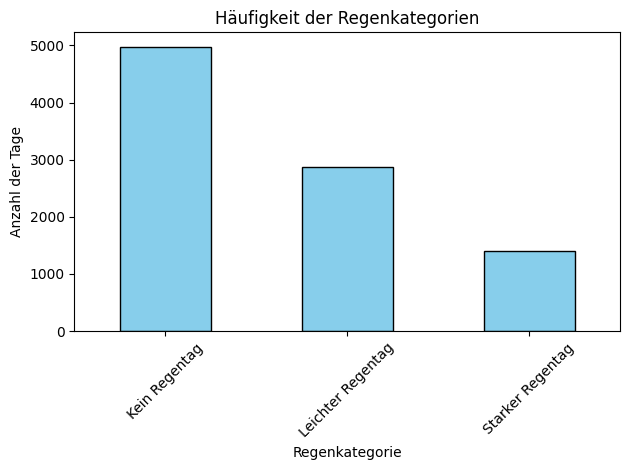

In [155]:
# Häufigkeiten zählen
regen_counts = df_2000_2025["Regentag_Kategorie"].value_counts()

# Balkendiagramm plotten
regen_counts.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Häufigkeit der Regenkategorien")
plt.xlabel("Regenkategorie")
plt.ylabel("Anzahl der Tage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Korrelations Plot

Damit wir die Auswahl der Variablen fundiert treffen können untersuchen wir die Korrelationen der einzelnen
Beobachtungen. Unsere Wahl fällt dann auf die Beobachtung welche einerseits die höchste Korrelation zum
Niederschlag hat, sowie auf die Beobachtung welche aus meteorologischer Sicht Sinn macht.

// Um die Auswahl der Variablen fundiert treffen zu können, untersuchen wir die Korrelationen zwischen den einzelnen
Beobachtungen. Unsere Wahl fällt dann auf die Beobachtung, die einerseits die höchste Korrelation mit dem
Niederschlag hat und andererseits aus meteorologischer Sicht sinnvoll ist.

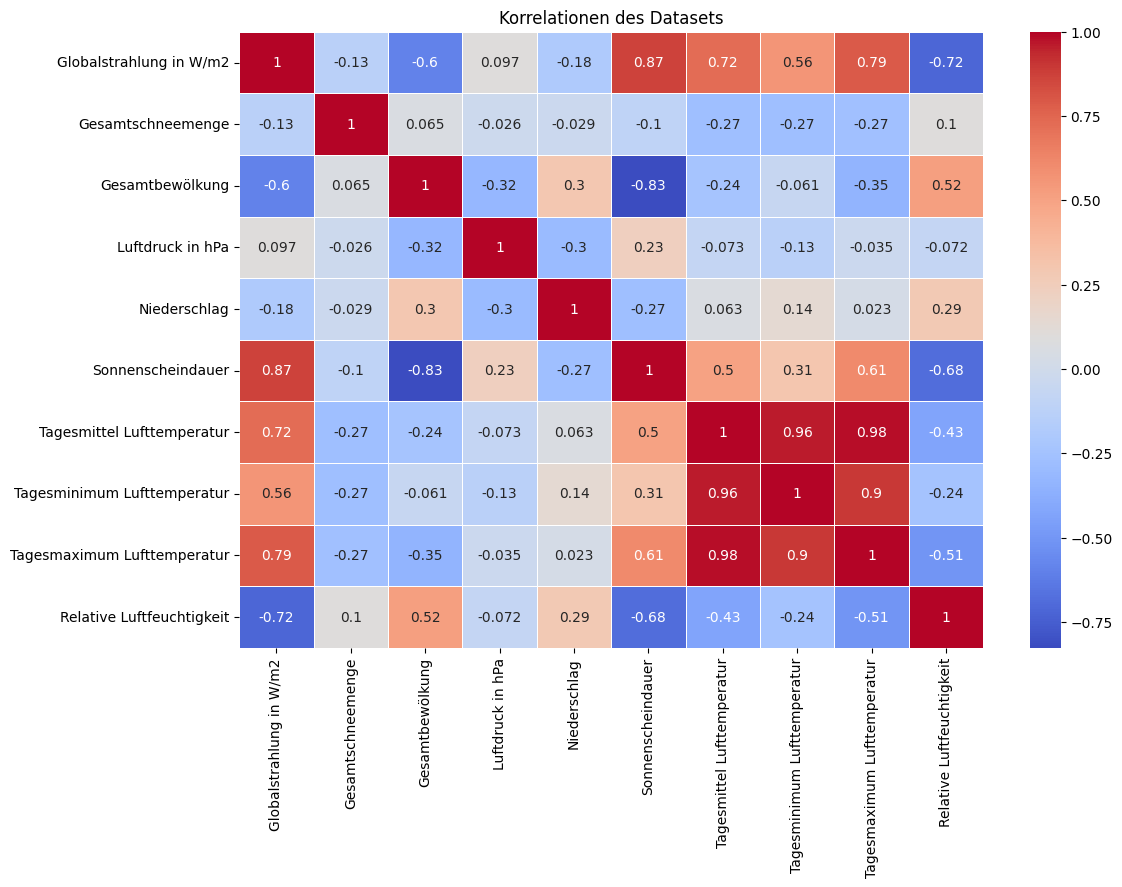

In [147]:
# Zusammenfügen der Daten über die letzten fünf Jahre
df_2000_2025_for_corr = df_2000_2025[[
    'Globalstrahlung in W/m2',
    'Gesamtschneemenge',
    'Gesamtbewölkung',
    'Luftdruck in hPa',
    'Niederschlag',
    'Sonnenscheindauer',
    'Tagesmittel Lufttemperatur',
    'Tagesminimum Lufttemperatur',
    'Tagesmaximum Lufttemperatur',
    'Relative Luftfeuchtigkeit'
]]

# Korrelationen erkennen
df_correlation = df_2000_2025_for_corr.corr()

plt.figure(figsize = (12, 8))
sns.heatmap(df_correlation, annot=True, cmap='coolwarm', linewidths=.5)
plt.title("Korrelationen des Datasets")
plt.show()

## Analyse der Korrelationen
Damit wir nicht auf eine unübersichtliche Matrix schauen müssen ordnen wir die Werte der Korrelation der Grösse nach und
veranschaulichen die Werte in einem Barplot.

Gesamtbewölkung                0.297429
Relative Luftfeuchtigkeit      0.285895
Tagesminimum Lufttemperatur    0.138900
Tagesmittel Lufttemperatur     0.063360
Tagesmaximum Lufttemperatur    0.022968
Name: Niederschlag, dtype: float64


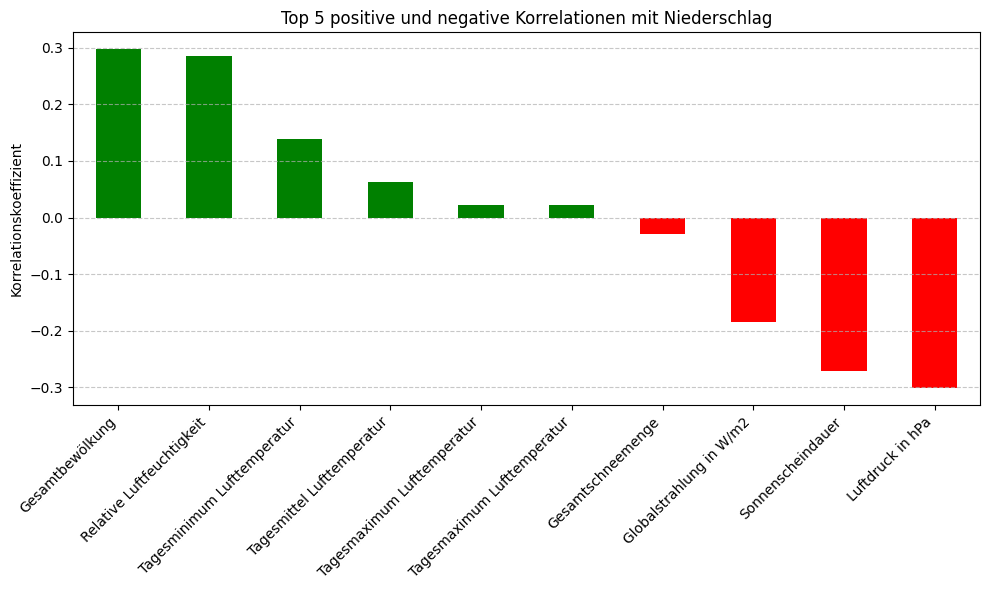

In [148]:
# Höchste wie tiefste Korrelationen
df_correlation_highest = (df_correlation["Niederschlag"].drop("Niederschlag")
                          .sort_values(ascending=False)).head(5)
print(df_correlation_highest)
df_correlation_lowes = (df_correlation["Niederschlag"]
                        .drop("Niederschlag").sort_values(ascending=True)).head(5)

combined_corr = (pd.concat([df_correlation_highest, df_correlation_lowes])
                 .sort_values(ascending=False))

plt.figure(figsize=(10, 6))
combined_corr.plot(kind='bar', color=['green' if corr > 0 else 'red' for corr in combined_corr.values])
plt.title("Top 5 positive und negative Korrelationen mit Niederschlag")
plt.ylabel("Korrelationskoeffizient")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Statistische Tests:
Damit wir nachweisen können, dass bei unseren gewählten Variablen tatsächlich ein linearer Zusammenhang vorliegt, wenden wir den Pearson Test an. Dieser gibt uns den Pearson-Korrelationskoeffizient an, dieser Wert r misst, wie stark und in welche Richtung zwei metrische Variablen linear zusammenhängen.

In [149]:
# Mit Spearman die Variablen herausfinden

results = []

for col in df_2000_2025_for_corr.columns:
    if col != 'Niederschlag':
        rho, p = spearmanr(df_2000_2025[col], df_2000_2025['Niederschlag'])
        results.append({
            'Variable': col,
            'Spearman-Korrelation': rho,
            'p-Wert': p,
            'Signifikant (p<0.05)': p < 0.05
        })
df_results = pd.DataFrame(results)
df_results.sort_values(by=['Spearman-Korrelation'], ascending=False, inplace=True)
df_results

,Variable,Spearman-Korrelation,p-Wert,Signifikant (p<0.05)
2,Gesamtbewölkung,0.513187,0.000000e+00,True
8,Relative Luftfeuchtigkeit,0.383397,0.000000e+00,True
6,Tagesminimum Lufttemperatur,0.099134,1.192317e-21,True
1,Gesamtschneemenge,-0.005286,6.111196e-01,False
5,Tagesmittel Lufttemperatur,-0.018234,7.943598e-02,False
7,Tagesmaximum Lufttemperatur,-0.086632,6.920342e-17,True
0,Globalstrahlung in W/m2,-0.341975,3.310006e-252,True
3,Luftdruck in hPa,-0.458368,0.000000e+00,True
4,Sonnenscheindauer,-0.483404,0.000000e+00,True


Wenn wir den Plot ansehen dann fällt auf, dass die Gesamtbewölkung respektive der Luftdruck am stärksten positiv wie negativ korreliert.
Was ebenfalls im Vergleich zu den anderen Beobachtungen hohe wie tiefe Korrelationswerte hat, ist die Relative Luftfeuchtigkeit und die
Sonnenscheindauer. Die restlichen Werte sind nahe Nul, was nicht unbedingt auf einen nicht vorhandenen Zusammenhang hindeutet, jedoch
zu bedeuten hat, dass kein linearer Zusammenhang zu identifizieren ist.

### Zusammenhängende Variablen:

### Die Gesamtbewölkung:
Zusammenhang zwischen Gesamtbewölkung und Niederschlag:
Eine positive Korrelation zwischen der Häufigkeit von Bewölkung und der Menge des Niederschlags wurde in mehreren Studien festgestellt. So zeigt eine Untersuchung, dass eine Zunahme der Bewölkungshäufigkeit mit einer Zunahme des Niederschlags einhergeht, während bei fehlender Bewölkung kein Niederschlag auftritt Nature https://www.nature.com/articles/s41597-021-01084-6?utm_source=chatgpt.com.
Darüber hinaus wurde festgestellt, dass starke Niederschläge häufig mit konvektiven Wolken verbunden sind, während leichte Niederschläge eher mit niedrigen Wolken auftreten rmets.onlinelibrary.wiley.com.
Einfluss der Bewölkung auf die Temperatur und den Wasserkreislauf:
Die Bewölkung beeinflusst nicht nur den Niederschlag, sondern auch die Temperaturen in Bodennähe. Tagsüber können Wolken die solare Einstrahlung abschatten, was zu niedrigeren Temperaturen führt. In wolkenlosen Nächten hingegen sinkt die Temperatur nahe dem Boden deutlich, da die langwellige Gegenstrahlung von Wolken fehlt .iac.ethz.ch+1iacweb.ethz.ch+1iacweb.ethz.ch+1iac.ethz.ch+1
Fazit
Die Gesamtbewölkung ist ein wichtiger Indikator für Niederschlag, da sie die physikalische Grundlage für Regen bildet. Allerdings ist der Zusammenhang komplex und hängt von verschiedenen Faktoren wie der Art der Wolken, ihrer Höhe und den meteorologischen Bedingungen ab. Eine hohe relative Luftfeuchtigkeit begünstigt die Wolkenbildung und erhöht somit die Wahrscheinlichkeit für Niederschlag.


### Die Luftfeuchtigkeit:
Wenn die relative Luftfeuchtigkeit hoch ist, steigt die Wahrscheinlichkeit, dass der Sättigungspunkt
überschritten wird, sprich es Regnet. Wie viel Wasser die Luft aufnehmen kann hängt dabei von der
Temperatur ab.
(Stadler Form Luftfeuchtigkeit messen, 2023)„Luftfeuchtigkeitswerte beeinflussen Wetterberechnungen z.B. durch die Wasserdampfbilanzgleichung – diese Formel drückt den Einfluss der Luftfeuchtigkeit durch Regen und Kondensation aus und umgekehrt.“(Process Sensing Technologies, 2023)

### Der Luftdruck:
Sinkt der atmosphärische Luftdruck, ist dies häufig ein Hinweis auf das Herannahen eines Tiefdruckgebiets – solche Gebiete sind typischerweise mit feuchter Luft und instabilen Wetterlagen verbunden. In einem Tief steigt die Luft auf, kühlt sich dabei ab, und der in der Luft enthaltene Wasserdampf kondensiert zu Wolken und schließlich zu Niederschlag. Umgekehrt steht hoher Luftdruck meist für stabiles, trockenes Wetter, da die Luft absinkt und sich erwärmt, wodurch Wolkenbildung und Regen unterdrückt werden.

„Tiefdruckgebiete führen in der Regel zu aufsteigender Luft, was zu Abkühlung, Kondensation und folglich zu Niederschlag führt. Hoher Luftdruck hingegen begünstigt absinkende, trockene Luftmassen.“
(Deutscher Wetterdienst, 2022)

„Luftdruckveränderungen sind zentrale Steuerungsmechanismen für Wettersysteme und beeinflussen die Niederschlagswahrscheinlichkeit maßgeblich.“
(MeteoSchweiz, 2023)

### Der Scope:


### Die Jahreszeiten - Faktor Zeit
Da es über die verschiedenen Jahreszeiten bzw. Monaten nicht gleich viel Regnet nehmen wir an, dass dies ebenfalls in unserem Modell berücksichtigt werden sollte, sollte sich ein Muster erkennen lassen. Falls dies nicht so wäre, so ist diese zeitliche Komponente nicht hilfreich für das Bestimmen der Regenwahrscheinlichkeit.

/var/folders/sc/hk55c1v54g3dff0094vmwkb80000gn/T/ipykernel_18059/771472963.py:13: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 4))


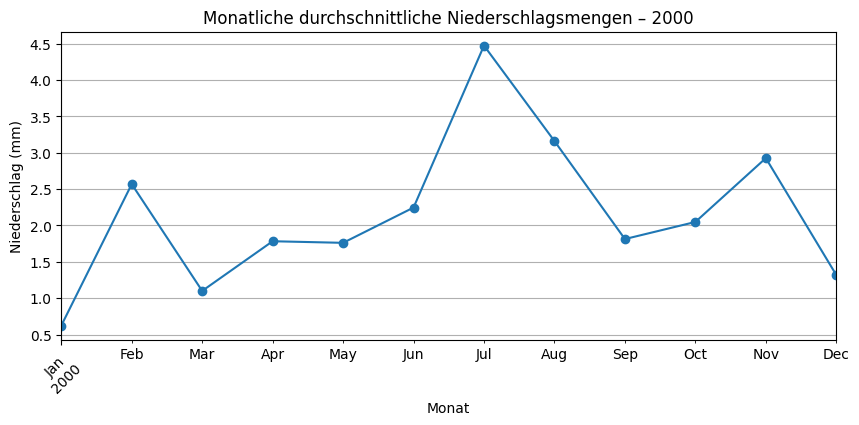

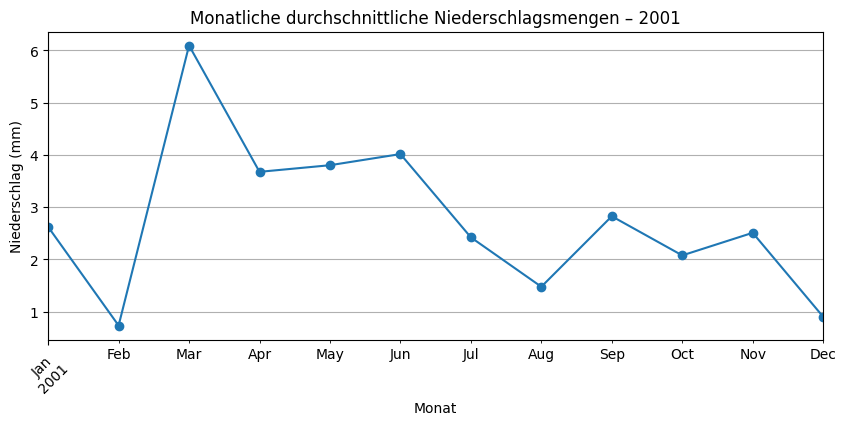

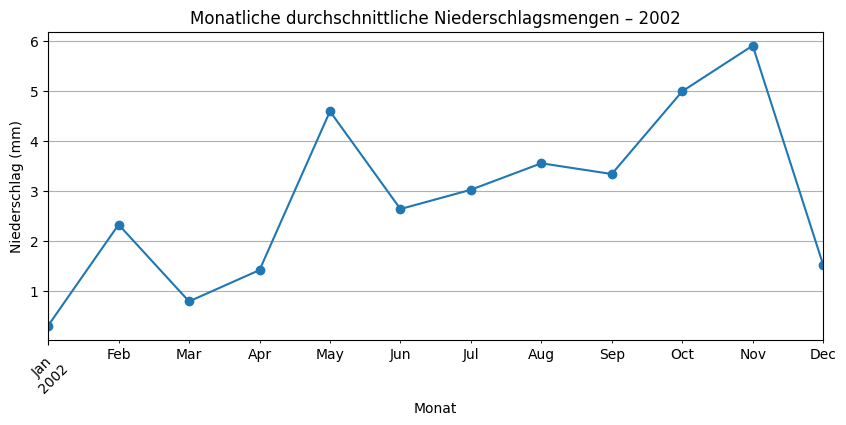

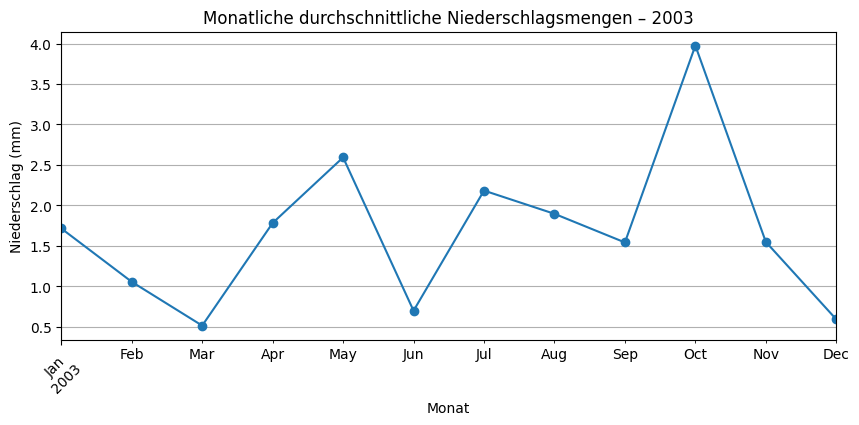

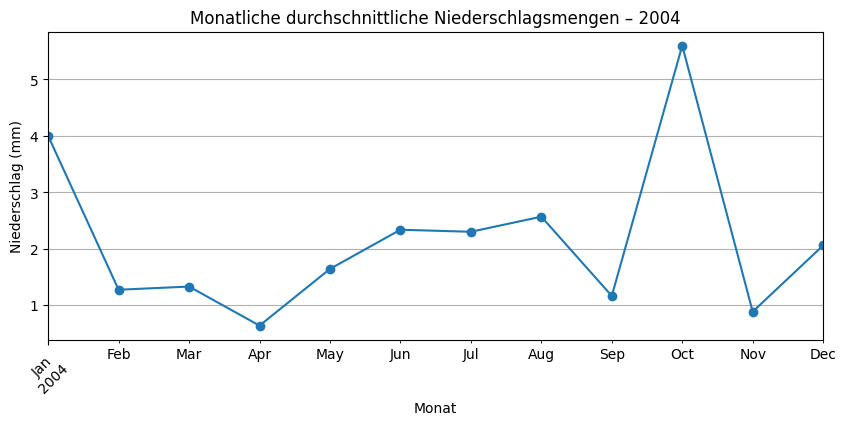

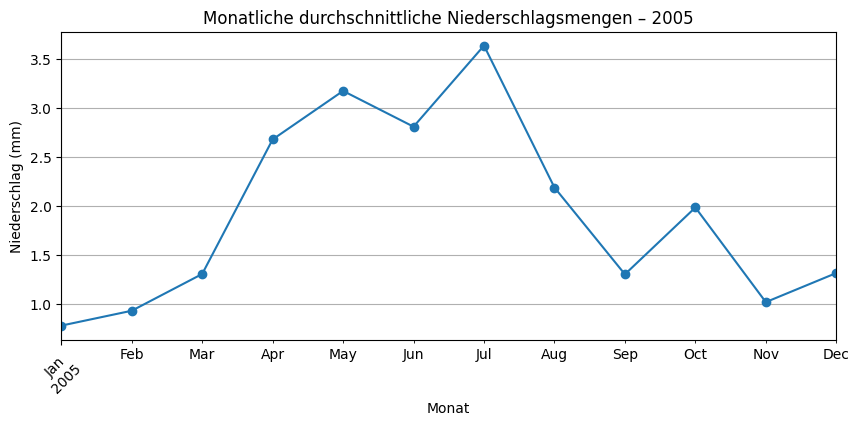

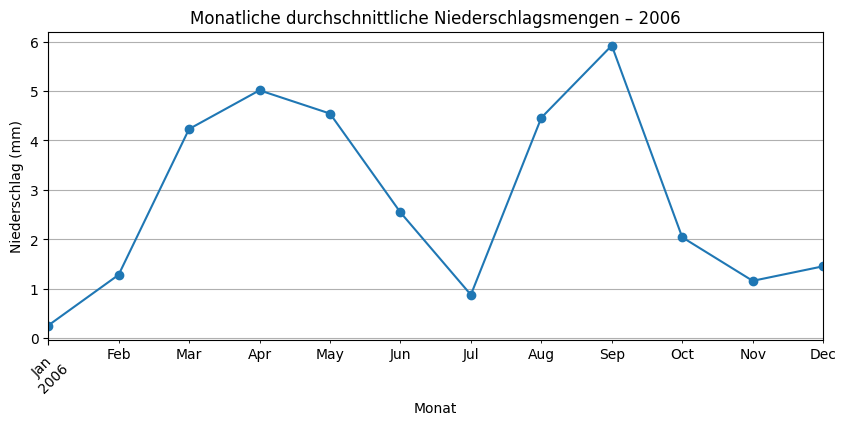

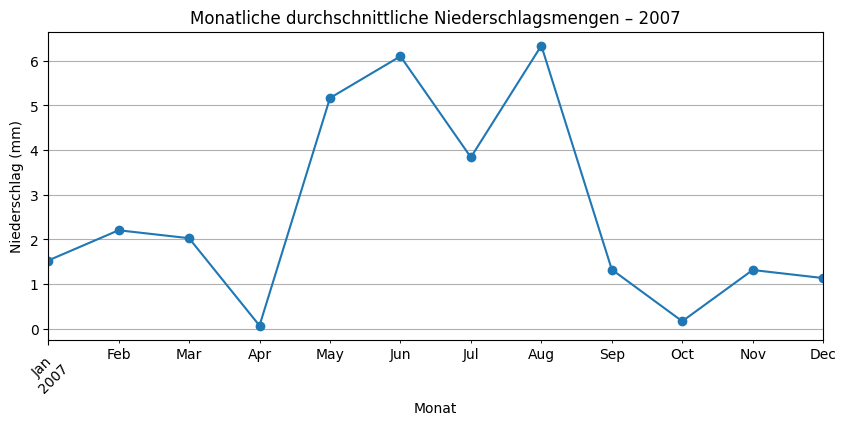

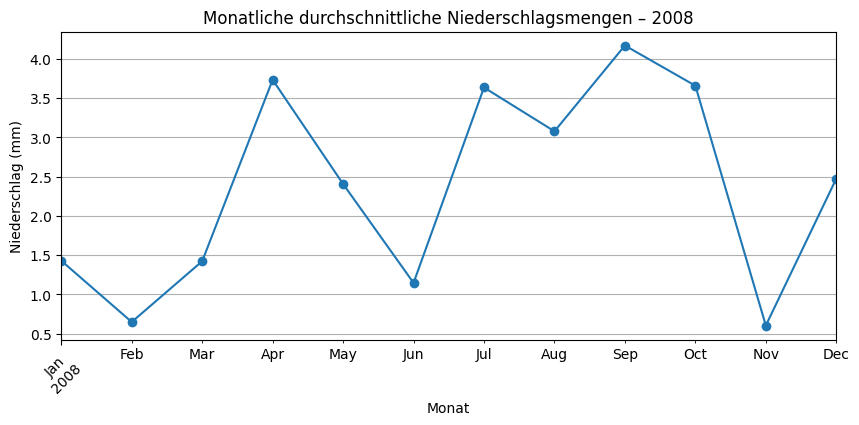

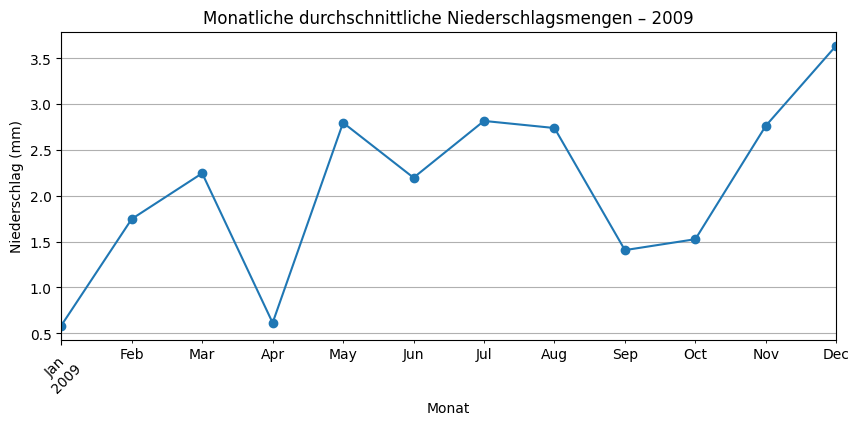

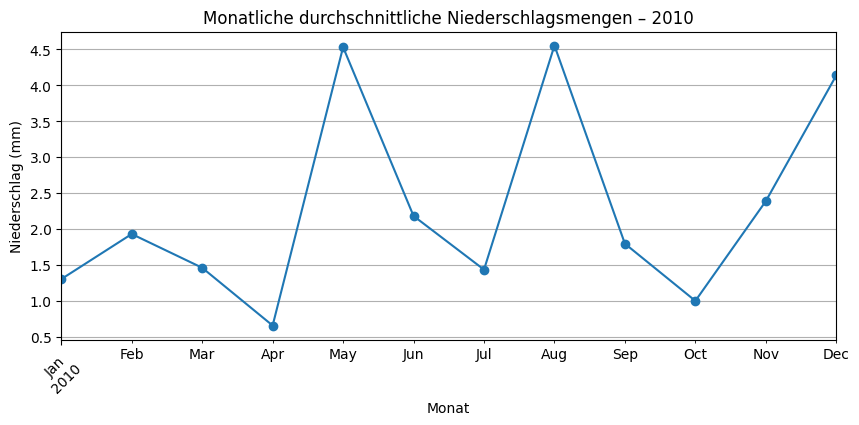

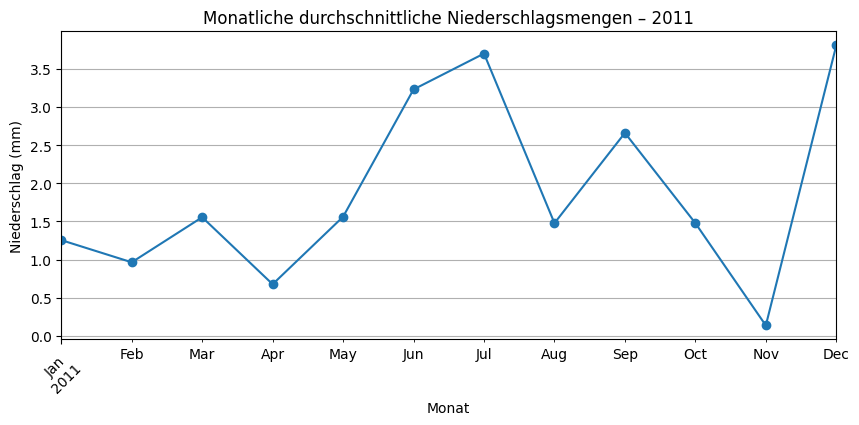

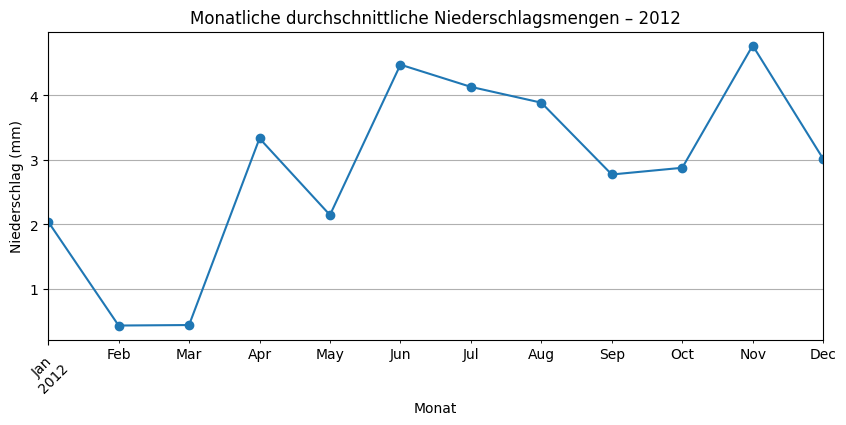

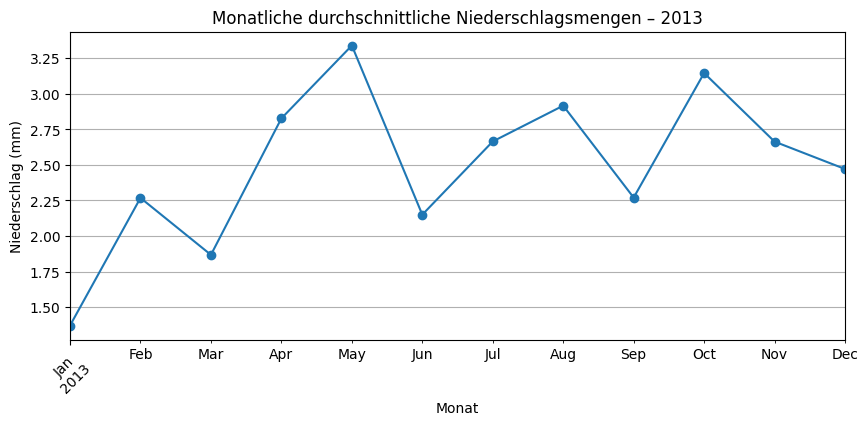

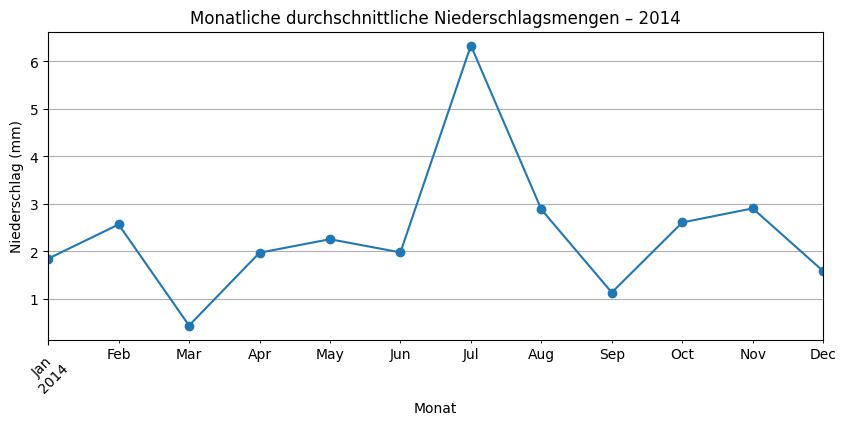

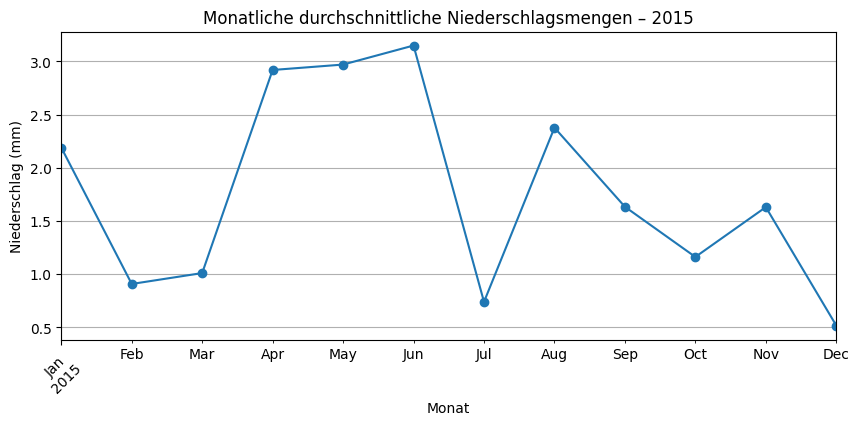

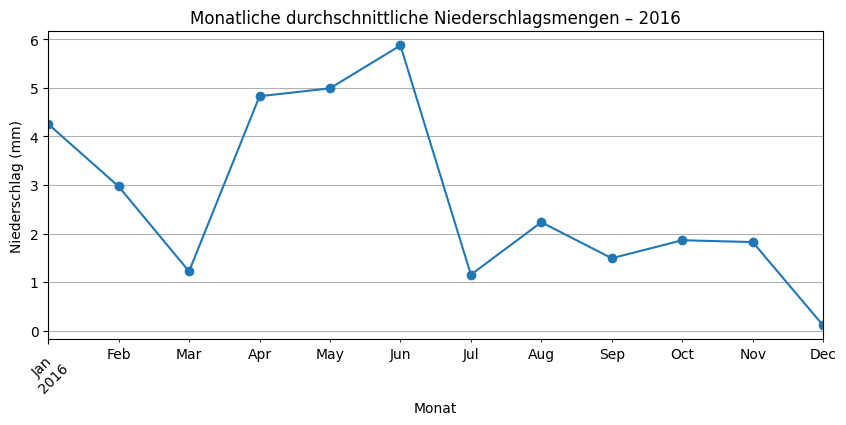

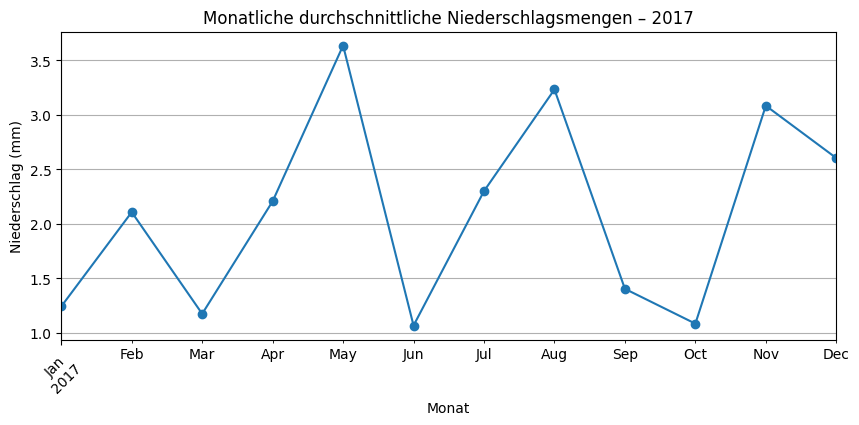

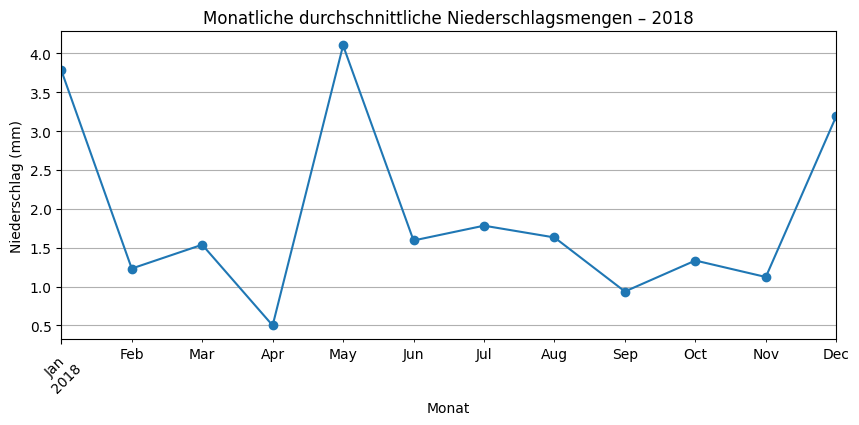

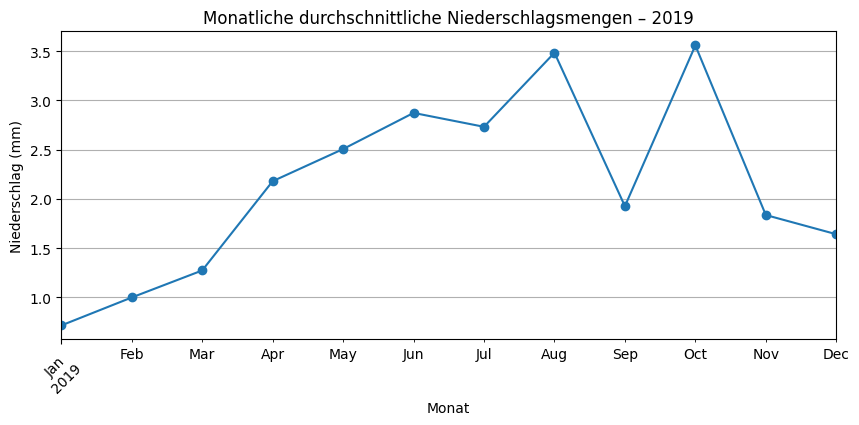

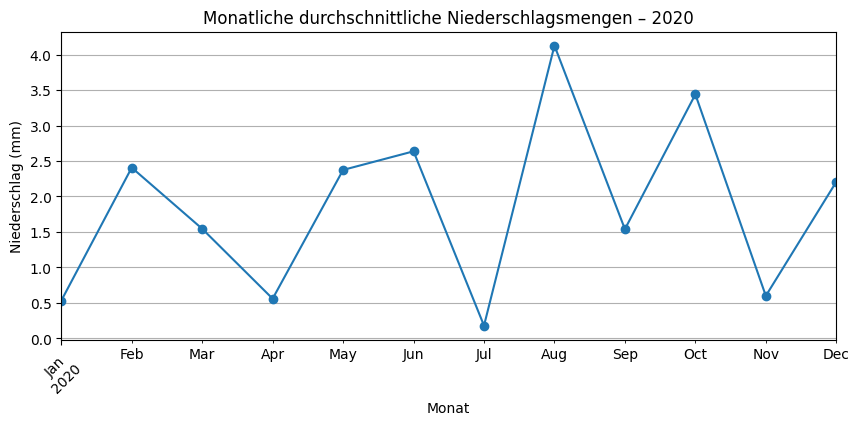

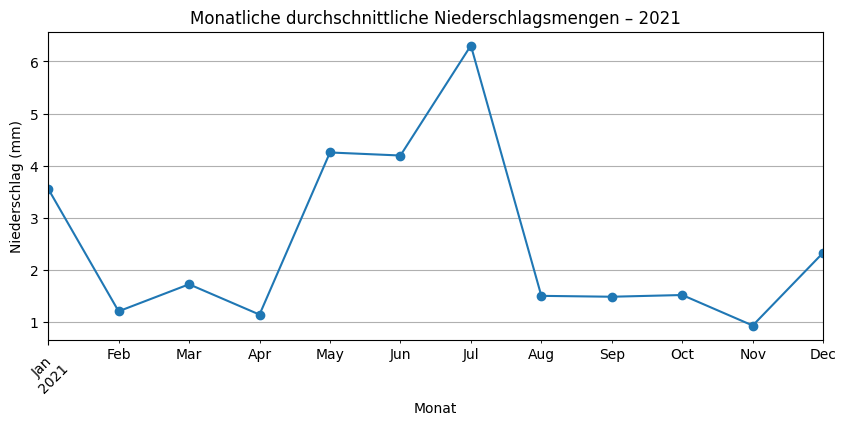

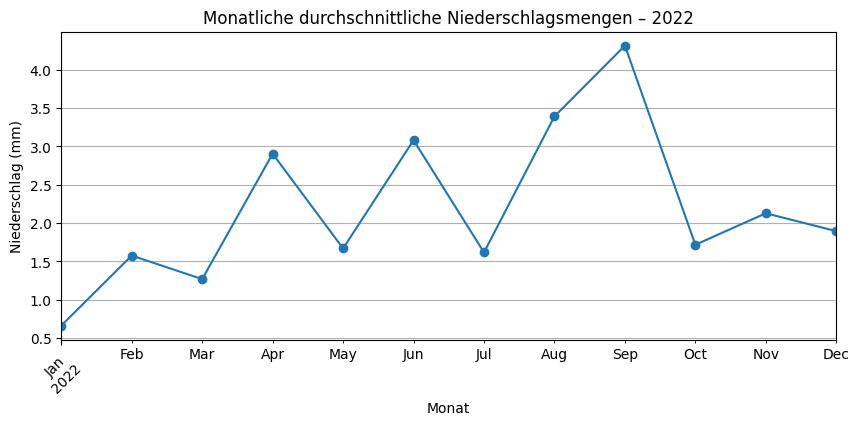

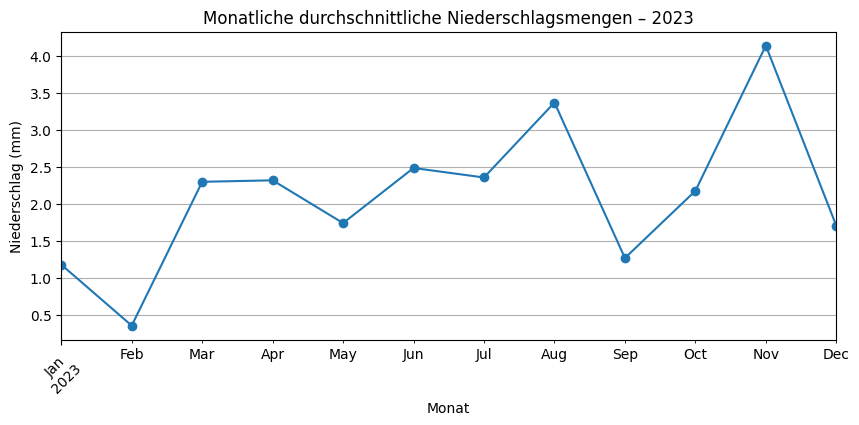

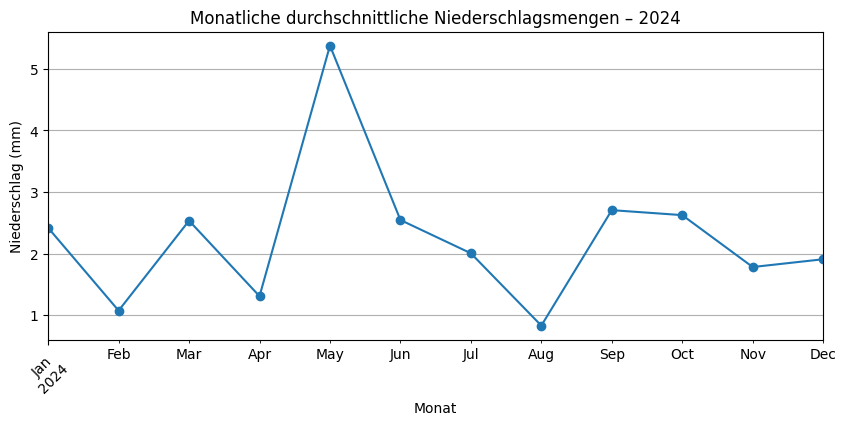

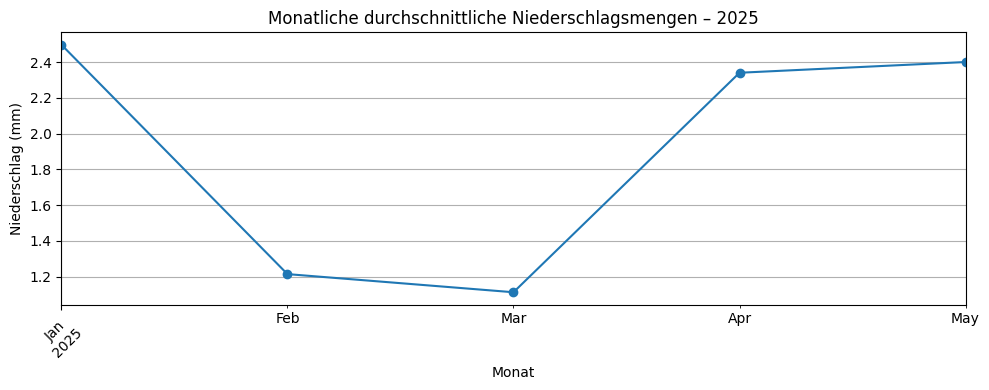

In [150]:
df_time_niederschlag = df_2000_2025[['Datum', 'Niederschlag']]

df_time_niederschlag.set_index('Datum', inplace=True)

# Jahresliste (optional automatisch aus den Daten extrahieren)
jahre = df_time_niederschlag.index.year.unique()

# Plot pro Jahr
for jahr in sorted(jahre):
    # Daten für das Jahr filtern und monatlich mitteln
    monthly_avg = df_time_niederschlag[df_time_niederschlag.index.year == jahr]['Niederschlag'].resample('ME').mean()

    plt.figure(figsize=(10, 4))
    monthly_avg.plot(marker='o')
    plt.title(f"Monatliche durchschnittliche Niederschlagsmengen – {jahr}")
    plt.xlabel("Monat")
    plt.ylabel("Niederschlag (mm)")
    plt.grid(True)
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Wahrscheinlichkeitsmodell

- Logistische Regression
eignet sich gut um die Vorhersage aufgrund historischer Daten zu trainieren und mit Daten abzufragen

# Abhängigkeiten und Unsicherheiten

# Erweiterung durch neue Erkenntnisse